# 01 Data audit, cleaning and baselines

This notebook loads the SKIPP'D train and test splits, checks the timestamps against the sun's position, audits the PV readings and camera frames, builds the cleaned forecast windows and computes the persistence and CNN baselines on the raw and cleaned test sets.

Run on a Colab GPU runtime. Data and checkpoints are saved to `MyDrive/UROP/`, so the notebook can be re-run after a disconnect and continues from the last saved epoch.

In [1]:
!pip install -q datasets pvlib
from google.colab import drive
drive.mount('/content/drive')
OUT = '/content/drive/MyDrive/UROP'
LOCAL_CACHE = '/content/skippd_cache'

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.4/19.4 MB 92.5 MB/s eta 0:00:00
Mounted at /content/drive


In [2]:
import os, shutil, time, math, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

os.makedirs(f'{OUT}/figs', exist_ok=True)
os.makedirs(f'{OUT}/ckpt', exist_ok=True)
os.makedirs(f'{OUT}/cache', exist_ok=True)
os.makedirs(LOCAL_CACHE, exist_ok=True)

SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device, '| outputs ->', OUT)

device: cuda | outputs -> /content/drive/MyDrive/UROP


In [3]:
INPUT_LEN, HORIZON = 15, 15
LAT, LON, ALT = 37.4275, -122.1697, 23
PANEL_TILT, PANEL_AZIMUTH, PANEL_KW_DC = 22.5, 195, 30.1

CLEAN = dict(
    max_zenith=85.0,
    neg_kw=-0.5,
    over_cap=1.05,
    cs_ratio_max=1.6,
    stuck_min=10,
    spike_kw=8.0,
    img_dark=15,
    img_saturated=245,
    img_flat_std=3.0,
    img_frozen_run=3,
    max_step_min=1.0,
)
RAW_MAX_GAP_MIN = 2.0

TRAIN = dict(batch=256, lr=1e-3, max_epochs=30, patience=5, val_frac_days=0.15)
RUN = 'day1b'
TRAIN_RAW_TOO = True

RESULTS_CSV = f'{OUT}/results.csv'
RESULT_COLS = ['when','run','train_data','test_set','model','n','rmse','mae','skill_rmse_vs_smart','skill_mae_vs_smart','notes']
def log_result(**row):
    row['when'] = pd.Timestamp.now().isoformat(timespec='seconds')
    df = pd.DataFrame([{c: row.get(c, '') for c in RESULT_COLS}])
    df.to_csv(RESULTS_CSV, mode='a', header=not os.path.exists(RESULTS_CSV), index=False)
    print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in row.items() if k != 'when'})

## 1. Load data
Images are stored as `uint8` and converted to floats one batch at a time, so the full training split fits in memory. `img_idx` maps each time-sorted row to its image.

In [4]:
def load_split(split):
    names = ['img', 'pv', 'ts']
    local = {k: f'{LOCAL_CACHE}/{split}_{k}.npy' for k in names}
    drive_ = {k: f'{OUT}/cache/{split}_{k}.npy' for k in names}

    if not all(os.path.exists(p) for p in local.values()) and all(os.path.exists(p) for p in drive_.values()):
        print(f'[{split}] copying cache from Drive to local disk...')
        for k in names: shutil.copy(drive_[k], local[k])

    if all(os.path.exists(p) for p in local.values()):
        print(f'[{split}] loading from cache')
        img = np.load(local['img']); pv = np.load(local['pv']); ts_raw = np.load(local['ts'])
    else:
        from datasets import load_dataset
        print(f'[{split}] downloading from Hugging Face (first run only)...')
        ds = load_dataset('solarbench/SKIPPD', split=split)
        n = len(ds)
        img = np.empty((n, 64, 64, 3), dtype=np.uint8)
        pos = 0
        t0 = time.time()
        for b in ds.iter(batch_size=2000):
            arr = np.stack([np.asarray(im.convert('RGB')) for im in b['image']])
            img[pos:pos + len(arr)] = arr
            pos += len(arr)
            if pos % 50000 < 2000: print(f'  {pos}/{n} images  ({time.time()-t0:.0f}s)')
        pv = np.asarray(ds['pv'], dtype=np.float32)
        t = pd.to_datetime(ds['time'])
        if t.tz is not None:
            t = t.tz_convert('UTC').tz_localize(None)
        ts_raw = t.values.astype('datetime64[ns]')
        for k, v in [('img', img), ('pv', pv), ('ts', ts_raw)]:
            np.save(local[k], v); shutil.copy(local[k], drive_[k])
        print(f'[{split}] cached to Drive')

    order = np.argsort(ts_raw, kind='stable')
    return dict(name=split, img=img, img_idx=order, pv=pv[order].astype(np.float32),
                ts=pd.DatetimeIndex(ts_raw[order]))

In [5]:
TR = load_split('train')
TE = load_split('test')
for D in (TR, TE):
    print(f"{D['name']}: {len(D['pv'])} rows, {D['ts'][0]} -> {D['ts'][-1]}, images {D['img'].shape} {D['img'].dtype}")

[train] downloading from Hugging Face (first run only)...


README.md:   0%|          | 0.00/12.3k [00:00<?, ?B/s]

ground/train-00000-of-00005.parquet: reconstructing file:   0%|          |  0.00B /  448MB            

ground/train-00000-of-00005.parquet: downloading bytes:           |  0.00B            

ground/train-00001-of-00005.parquet: reconstructing file:   0%|          |  0.00B /  455MB            

ground/train-00001-of-00005.parquet: downloading bytes:           |  0.00B            

... (7 outputs left out)

ground/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/349372 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/14003 [00:00<?, ? examples/s]

  50000/349372 images  (14s)
  100000/349372 images  (30s)
  150000/349372 images  (44s)
  200000/349372 images  (59s)
  250000/349372 images  (73s)
  300000/349372 images  (86s)
[train] cached to Drive
[test] downloading from Hugging Face (first run only)...
[test] cached to Drive
train: 349372 rows, 2017-03-09 14:47:00 -> 2019-10-27 01:59:20, images (349372, 64, 64, 3) uint8
test: 14003 rows, 2017-06-24 14:38:40 -> 2019-10-20 02:15:30, images (14003, 64, 64, 3) uint8


## 2. Timezone and clock-offset check
First, which timezone the timestamps are in (tested on clear days). Second, whether a clock offset remains: on clear days across the year, the clear-sky curve is shifted earlier or later until it best matches measured PV. An offset of about 60 min during daylight saving and 0 otherwise means the timestamps were converted with a fixed 8 h offset. The correction is only applied to the sun-position calculations.

Days are grouped by Stanford local date (UTC − 8 h).

/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2999: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3000: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


         hypothesis  median_corr_on_clear_days
                UTC                   0.854802
America/Los_Angeles                  -0.778738
          Etc/GMT+8                        NaN
==> timezone: UTC

79 clear days. Median best shift: daylight-saving days 60.0 min, standard-time days 0.0 min
==> offset changes with daylight saving (timestamps built with a fixed +8 h from local clock time). Correction applied to sun-position time: {'dst_min': 60, 'std_min': 0}


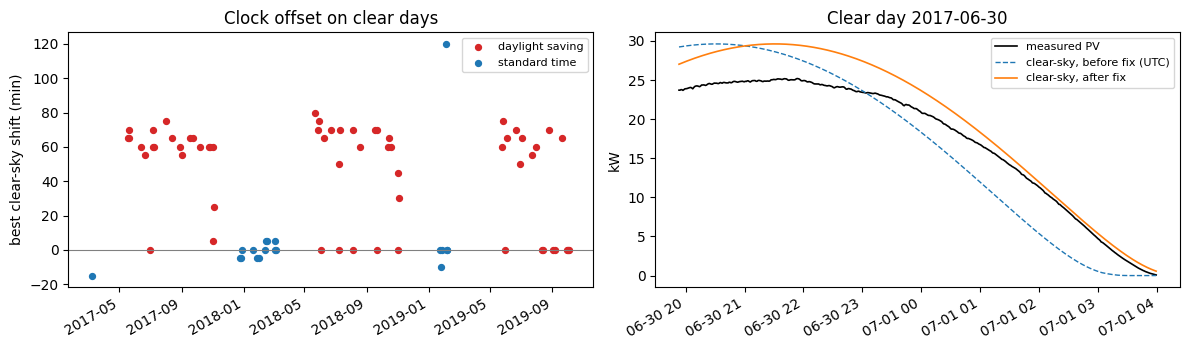

In [6]:
from pvlib.location import Location
from pvlib import irradiance
SITE = Location(LAT, LON, altitude=ALT)
CLOCK_FIX = None

def solar_terms(ts_naive, tz):
    '''Clear-sky PV (kW) and solar zenith (deg) for naive timestamps interpreted in timezone tz.'''
    idx = pd.DatetimeIndex(ts_naive)
    aware = idx.tz_localize('UTC') if tz == 'UTC' else idx.tz_localize(tz, ambiguous='NaT', nonexistent='NaT')
    ok = ~aware.isna()
    cs_kw = np.full(len(idx), np.nan, dtype=np.float32)
    zen = np.full(len(idx), np.nan, dtype=np.float32)
    a = aware[ok]
    cs = SITE.get_clearsky(a, model='ineichen')
    sp = SITE.get_solarposition(a)
    poa = irradiance.get_total_irradiance(PANEL_TILT, PANEL_AZIMUTH, dni=cs['dni'], ghi=cs['ghi'], dhi=cs['dhi'],
                                          solar_zenith=sp['apparent_zenith'], solar_azimuth=sp['azimuth'])
    cs_kw[ok] = np.clip(PANEL_KW_DC * poa['poa_global'].values / 1000.0, 0, PANEL_KW_DC)
    zen[ok] = sp['apparent_zenith'].values
    return cs_kw, zen

def local_date(ts):
    '''Calendar date at Stanford (UTC-8), used to group readings into days.'''
    return np.array((pd.DatetimeIndex(ts) - pd.Timedelta(hours=8)).date)

def day_roughness(D, min_rows=300):
    df = pd.DataFrame({'pv': D['pv']}, index=D['ts'])
    out = {}
    for day, g in df.groupby(local_date(D['ts'])):
        if len(g) < min_rows or g.pv.max() < 15: continue
        out[day] = np.abs(np.diff(g.pv.values)).sum() / max(g.pv.values.sum(), 1e-6)
    return pd.Series(out).sort_values()

ROUGH = day_roughness(TR)
LD_TR = local_date(TR['ts'])

HYPS = ['UTC', 'America/Los_Angeles', 'Etc/GMT+8']
days = list(ROUGH.index[:15])
sel = np.isin(LD_TR, days)
tz_rows = []
for h in HYPS:
    cs_h, _ = solar_terms(TR['ts'][sel], h)
    cors = []
    for d in days:
        m = LD_TR[sel] == d
        ok = ~np.isnan(cs_h[m])
        if ok.sum() > 50: cors.append(np.corrcoef(TR['pv'][sel][m][ok], cs_h[m][ok])[0, 1])
    tz_rows.append(dict(hypothesis=h, median_corr_on_clear_days=np.median(cors)))
tz_table = pd.DataFrame(tz_rows)
print(tz_table.to_string(index=False))
TZ = tz_table.sort_values('median_corr_on_clear_days', ascending=False).iloc[0].hypothesis
print(f'==> timezone: {TZ}\n')

def best_lag(D, ld, d, tz, lags=np.arange(-120, 125, 5)):
    m = ld == d
    p = pd.Series(D['pv'][m], index=D['ts'][m]); p = p[~p.index.duplicated()]
    grid = pd.date_range(p.index.min() - pd.Timedelta(minutes=150), p.index.max() + pd.Timedelta(minutes=150), freq='1min')
    cs = pd.Series(solar_terms(grid, tz)[0], index=grid)
    pv_g = p.reindex(grid)
    best = (0, -2.0)
    for L in lags:
        c = cs.shift(int(L))
        ok = pv_g.notna() & c.notna()
        if ok.sum() < 100: continue
        r = np.corrcoef(pv_g[ok], c[ok])[0, 1]
        if r > best[1]: best = (int(L), r)
    return best

def is_dst(d):
    return bool((pd.Timestamp(d) + pd.Timedelta(hours=12)).tz_localize('America/Los_Angeles').dst())

r_df = pd.DataFrame({'day': ROUGH.index, 'rough': ROUGH.values})
r_df['month'] = [ (d.year, d.month) for d in r_df.day ]
lag_days = r_df.groupby('month').head(3).day.tolist()
lag_rows = []
for d in lag_days:
    L, r = best_lag(TR, LD_TR, d, TZ)
    lag_rows.append(dict(day=d, dst=is_dst(d), best_lag_min=L, corr=r))
lag_df = pd.DataFrame(lag_rows).sort_values('day')
med_dst = lag_df[lag_df.dst].best_lag_min.median() if lag_df.dst.any() else np.nan
med_std = lag_df[~lag_df.dst].best_lag_min.median() if (~lag_df.dst).any() else np.nan
print(f'{len(lag_df)} clear days. Median best shift: daylight-saving days {med_dst} min, standard-time days {med_std} min')

if CLOCK_FIX is None:
    s_dst = 0 if np.isnan(med_dst) else med_dst
    s_std = 0 if np.isnan(med_std) else med_std
    if abs(s_dst - s_std) >= 30:
        std = int(5 * round(s_std / 5)) if abs(s_std) >= 15 else 0
        CLOCK_FIX = {'dst_min': std + 60 * int(round((s_dst - s_std) / 60)), 'std_min': std}
        verdict = 'offset changes with daylight saving (timestamps built with a fixed +8 h from local clock time)'
    elif abs(np.nanmedian(lag_df.best_lag_min)) >= 15:
        c = int(5 * round(np.nanmedian(lag_df.best_lag_min) / 5))
        CLOCK_FIX = {'dst_min': c, 'std_min': c}
        verdict = 'constant clock offset all year'
    else:
        CLOCK_FIX = {'dst_min': 0, 'std_min': 0}
        verdict = 'no meaningful offset; clear-sky and PV line up'
elif CLOCK_FIX == 'none':
    CLOCK_FIX, verdict = {'dst_min': 0, 'std_min': 0}, 'forced: no correction'
else:
    verdict = 'forced by CONFIG'
print(f'==> {verdict}. Correction applied to sun-position time: {CLOCK_FIX}')
lag_df.to_csv(f'{OUT}/clock_offset_by_day.csv', index=False)
tz_table.to_csv(f'{OUT}/timezone_check.csv', index=False)

def solar_time(ts):
    '''Timestamp to use for sun position: reading time minus the detected clock offset.'''
    ts = pd.DatetimeIndex(ts)
    if CLOCK_FIX['dst_min'] != CLOCK_FIX['std_min']:
        ld = local_date(ts); lut = {d: is_dst(d) for d in set(ld)}
        dst = np.array([lut[d] for d in ld])
    else:
        dst = np.zeros(len(ts), bool)
    shift = np.where(dst, CLOCK_FIX['dst_min'], CLOCK_FIX['std_min'])
    return ts - pd.to_timedelta(shift, unit='min')

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
ax = axes[0]
for flag, col, lab in [(True, 'C3', 'daylight saving'), (False, 'C0', 'standard time')]:
    q = lag_df[lag_df.dst == flag]
    ax.scatter(pd.to_datetime(q.day), q.best_lag_min, color=col, s=18, label=lab)
ax.axhline(0, color='0.5', lw=.8)
ax.set_ylabel('best clear-sky shift (min)'); ax.set_title('Clock offset on clear days'); ax.legend(fontsize=8)
d0 = days[0]; m = LD_TR == d0
ax = axes[1]
ax.plot(TR['ts'][m], TR['pv'][m], color='k', lw=1.2, label='measured PV')
ax.plot(TR['ts'][m], solar_terms(TR['ts'][m], TZ)[0], color='C0', lw=1, ls='--', label=f'clear-sky, before fix ({TZ})')
ax.plot(TR['ts'][m], solar_terms(solar_time(TR['ts'][m]), TZ)[0], color='C1', lw=1.2, label='clear-sky, after fix')
ax.set_title(f'Clear day {d0}'); ax.set_ylabel('kW'); ax.legend(fontsize=8)
fig.autofmt_xdate(); fig.tight_layout(); fig.savefig(f'{OUT}/figs/clock_offset_check.png', dpi=150); plt.show()

In [7]:
for D in (TR, TE):
    D['cs'], D['zen'] = solar_terms(solar_time(D['ts']), TZ)
    D['cs_old'], _ = solar_terms(D['ts'], 'UTC')
    print(D['name'], 'clear-sky ready')

train clear-sky ready
test clear-sky ready


## 3. Data audit
Each check flags readings without removing anything. Thresholds are set in the CONFIG cell.

In [8]:
def image_stats(D, chunk=4096):
    n = len(D['pv']); mean = np.empty(n, np.float32); std = np.empty(n, np.float32); dprev = np.full(n, np.inf, np.float32)
    for i in range(0, n, chunk):
        j = min(i + chunk, n)
        lo = max(i - 1, 0)
        x = D['img'][D['img_idx'][lo:j]].astype(np.float32)
        xi = x[(i - lo):]
        mean[i:j] = xi.mean(axis=(1, 2, 3)); std[i:j] = xi.std(axis=(1, 2, 3))
        d = np.abs(x[1:] - x[:-1]).mean(axis=(1, 2, 3))
        dprev[lo + 1:j] = d
    return mean, std, dprev

def run_lengths(mask):
    '''For each position, length of the run of consecutive True values it belongs to (0 where False).'''
    out = np.zeros(len(mask), int)
    if not mask.any(): return out
    m = np.r_[False, mask, False].astype(int)
    starts = np.where(np.diff(m) == 1)[0]; ends = np.where(np.diff(m) == -1)[0]
    for s, e in zip(starts, ends): out[s:e] = e - s
    return out

def audit(D, c=CLEAN):
    pv, zen, cs = D['pv'], D['zen'], D['cs']
    n = len(pv)
    daylight = np.nan_to_num(zen, nan=180) < 80
    f = {}
    f['pv_missing'] = ~np.isfinite(pv)
    f['pv_negative'] = pv < c['neg_kw']
    f['pv_over_capacity'] = pv > c['over_cap'] * PANEL_KW_DC
    f['pv_far_above_clearsky'] = (np.nan_to_num(cs) > 2) & (pv > c['cs_ratio_max'] * np.nan_to_num(cs))
    same = np.r_[False, np.diff(pv) == 0]
    runs = run_lengths(same)
    stuck = (runs + 1 >= c['stuck_min']) & daylight & (pv > 0.5)
    stuck = stuck | np.r_[stuck[1:], False]
    f['pv_stuck'] = stuck
    d1 = np.r_[0.0, np.diff(pv)]; d2 = np.r_[np.diff(pv), 0.0]
    f['pv_spike'] = (np.abs(d1) > c['spike_kw']) & (np.abs(d2) > c['spike_kw']) & (np.sign(d1) == -np.sign(d2))
    mean, std, dprev = image_stats(D)
    D['img_mean'], D['img_std'] = mean, std
    f['img_dark_in_daylight'] = (mean < c['img_dark']) & daylight
    f['img_saturated'] = mean > c['img_saturated']
    f['img_blank'] = std < c['img_flat_std']
    frozen = run_lengths(dprev == 0)
    fr = frozen + 1 >= c['img_frozen_run']
    f['img_frozen'] = fr | np.r_[fr[1:], False]
    bad = np.zeros(n, bool)
    for v in f.values(): bad |= v
    f['ANY_bad_data'] = bad
    f['low_sun (filtered, not an error)'] = np.nan_to_num(zen, nan=180) > c['max_zenith']
    D['bad'] = bad
    D['good'] = ~bad & ~f['low_sun (filtered, not an error)']
    D['flags'] = f
    return pd.Series({k: int(v.sum()) for k, v in f.items()}, name=D['name'])

audit_tbl = pd.concat([audit(TR), audit(TE)], axis=1)
audit_tbl['train_%'] = (100 * audit_tbl['train'] / len(TR['pv'])).round(2)
audit_tbl['test_%'] = (100 * audit_tbl['test'] / len(TE['pv'])).round(2)
print(audit_tbl.to_string())
audit_tbl.to_csv(f'{OUT}/audit_flags.csv')

for D in (TR, TE):
    dt = np.diff(D['ts'].values).astype('timedelta64[s]').astype(float) / 60
    print(f"\n{D['name']} time steps: {np.mean(dt == 1)*100:.1f}% exactly 1 min, "
          f"{(dt > 1).sum()} gaps > 1 min, {(dt > 60).sum()} gaps > 1 h, {(dt <= 0).sum()} duplicates/out-of-order")

overlap = sorted(set(local_date(TR['ts'])) & set(local_date(TE['ts'])))
print(f'\nDays present in BOTH train and test: {len(overlap)}', overlap[:10])
print('Image mean brightness percentiles (train, daylight):',
      np.percentile(TR['img_mean'][TR['zen'] < 80], [0.1, 1, 50, 99, 99.9]).round(1))

                                  train  test  train_%  test_%
pv_missing                            0     0     0.00    0.00
pv_negative                           0     0     0.00    0.00
pv_over_capacity                      0     0     0.00    0.00
pv_far_above_clearsky                21     0     0.01    0.00
pv_stuck                            528     0     0.15    0.00
pv_spike                            128    15     0.04    0.11
img_dark_in_daylight                  0     0     0.00    0.00
img_saturated                         0     0     0.00    0.00
img_blank                             0     0     0.00    0.00
img_frozen                            0     0     0.00    0.00
ANY_bad_data                        677    15     0.19    0.11
low_sun (filtered, not an error)   6289   245     1.80    1.75

train time steps: 99.1% exactly 1 min, 719 gaps > 1 min, 535 gaps > 1 h, 0 duplicates/out-of-order

test time steps: 99.2% exactly 1 min, 34 gaps > 1 min, 19 gaps > 1 h, 0 duplicat

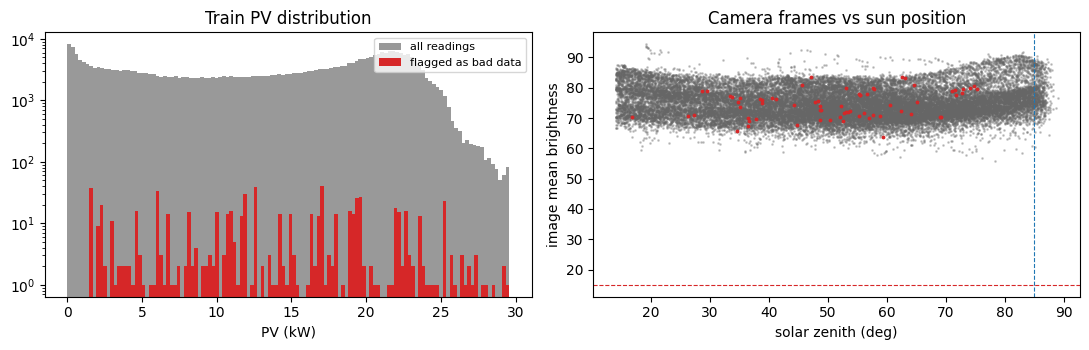

No camera-frame faults found in train (no dark, saturated, blank or frozen frames).


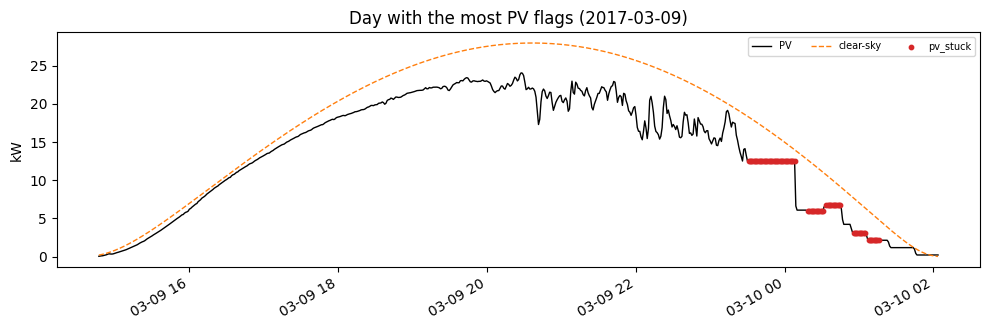

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(TR['pv'], bins=120, color='0.6', label='all readings')
axes[0].hist(TR['pv'][TR['bad']], bins=120, color='C3', label='flagged as bad data')
axes[0].set_yscale('log'); axes[0].set_xlabel('PV (kW)'); axes[0].set_title('Train PV distribution'); axes[0].legend(fontsize=8)
sub = np.random.default_rng(0).choice(len(TR['pv']), min(30000, len(TR['pv'])), replace=False)
axes[1].scatter(TR['zen'][sub], TR['img_mean'][sub], s=1, alpha=.3, color='0.4')
b = sub[TR['bad'][sub]]
axes[1].scatter(TR['zen'][b], TR['img_mean'][b], s=3, color='C3')
axes[1].axhline(CLEAN['img_dark'], ls='--', color='C3', lw=.8); axes[1].axvline(CLEAN['max_zenith'], ls='--', color='C0', lw=.8)
axes[1].set_xlabel('solar zenith (deg)'); axes[1].set_ylabel('image mean brightness'); axes[1].set_title('Camera frames vs sun position')
fig.tight_layout(); fig.savefig(f'{OUT}/figs/audit_overview.png', dpi=150); plt.show()

img_flags = [k for k in TR['flags'] if k.startswith('img_') and TR['flags'][k].any()]
if not img_flags:
  print('No camera-frame faults found in train (no dark, saturated, blank or frozen frames).')
if img_flags:
  fig, axes = plt.subplots(len(img_flags), 4, figsize=(8, 2.1 * len(img_flags)), squeeze=False)
  for r, k in enumerate(img_flags):
      ids = np.where(TR['flags'][k])[0]
      pick = np.unique(ids[np.linspace(0, len(ids) - 1, 4).astype(int)]) if len(ids) else []
      for cidx in range(4):
          ax = axes[r, cidx]; ax.axis('off')
          if cidx < len(pick):
              ax.imshow(TR['img'][TR['img_idx'][pick[cidx]]]); ax.set_title(str(TR['ts'][pick[cidx]])[:16], fontsize=7)
      axes[r, 0].text(-0.15, 0.5, k, transform=axes[r, 0].transAxes, ha='right', va='center', fontsize=8)
  fig.suptitle('Examples of flagged camera frames'); fig.tight_layout(); fig.savefig(f'{OUT}/figs/flagged_images.png', dpi=150); plt.show()

pv_flag = TR['flags']['pv_stuck'] | TR['flags']['pv_spike'] | TR['flags']['pv_far_above_clearsky'] | TR['flags']['pv_negative']
if pv_flag.any():
    ld_tr = local_date(TR['ts'])
    worst = pd.Series(pv_flag, index=ld_tr).groupby(level=0).sum().idxmax()
    m = ld_tr == worst
    fig, ax = plt.subplots(figsize=(10, 3.4))
    ax.plot(TR['ts'][m], TR['pv'][m], color='k', lw=1, label='PV')
    ax.plot(TR['ts'][m], TR['cs'][m], color='C1', lw=1, ls='--', label='clear-sky')
    for k, col in [('pv_stuck', 'C3'), ('pv_spike', 'C4'), ('pv_far_above_clearsky', 'C2'), ('pv_negative', 'C0')]:
        mm = m & TR['flags'][k]
        if mm.any(): ax.scatter(TR['ts'][mm], TR['pv'][mm], s=10, color=col, label=k, zorder=3)
    ax.set_title(f'Day with the most PV flags ({worst})'); ax.set_ylabel('kW'); ax.legend(fontsize=7, ncol=3)
    fig.autofmt_xdate(); fig.tight_layout(); fig.savefig(f'{OUT}/figs/worst_day.png', dpi=150); plt.show()

## 4. Forecast windows
A window is 15 one-minute PV readings and the current sky image, with the target 15 minutes later.
- Raw windows: the original rule (no gap over 2 min).
- Clean windows: one-minute steps and every reading passing the audit.

In [10]:
OFF = np.arange(-(INPUT_LEN - 1), 1)

def build_windows(D, max_step_min, use_good):
    ts_min = D['ts'].values.astype('datetime64[s]').astype(np.int64) / 60.0
    d = np.diff(ts_min)
    badstep = (d > max_step_min + 1e-6) | (d <= 0)
    cbad = np.r_[0, np.cumsum(badstep)]
    t = np.arange(INPUT_LEN - 1, len(ts_min) - HORIZON)
    start, end = t - (INPUT_LEN - 1), t + HORIZON
    ok = (cbad[end] - cbad[start]) == 0
    if use_good:
        cg = np.r_[0, np.cumsum(~D['good'])]
        ok &= (cg[end + 1] - cg[start]) == 0
    return t[ok]

for D in (TR, TE):
    D['w_raw'] = build_windows(D, RAW_MAX_GAP_MIN, use_good=False)
    D['w_clean'] = build_windows(D, CLEAN['max_step_min'], use_good=True)

win_tbl = pd.DataFrame({
    'raw windows': [len(TR['w_raw']), len(TE['w_raw'])],
    'clean windows': [len(TR['w_clean']), len(TE['w_clean'])],
}, index=['train', 'test'])
win_tbl['removed'] = win_tbl['raw windows'] - win_tbl['clean windows']
win_tbl['removed_%'] = (100 * win_tbl['removed'] / win_tbl['raw windows']).round(1)
print(win_tbl.to_string())
win_tbl.to_csv(f'{OUT}/windows_raw_vs_clean.csv')
print('\nSanity check: the old notebook had 13392 test windows. Raw test windows here:', len(TE['w_raw']))

       raw windows  clean windows  removed  removed_%
train       331826         320172    11654        3.5
test         13392          12777      615        4.6

Sanity check: the old notebook had 13392 test windows. Raw test windows here: 13392


## 5. Persistence baselines
`smart (old clear-sky)` reproduces the earlier RMSE of 3.702 kW. `smart` uses the corrected clock and is the reference for all skill scores.

In [11]:
def metrics(pred, true):
    return float(np.sqrt(np.mean((pred - true) ** 2))), float(np.mean(np.abs(pred - true)))

def persistence_preds(D, w, cs_key):
    last = D['pv'][w]
    k = last / np.maximum(D[cs_key][w], 1e-3)
    return last, np.clip(k * D[cs_key][w + HORIZON], 0, None)

BASE = {}
for split_key, label in [('w_raw', 'raw test'), ('w_clean', 'clean test')]:
    w = TE[split_key]; y = TE['pv'][w + HORIZON]
    naive, smart = persistence_preds(TE, w, 'cs')
    _, smart_old = persistence_preds(TE, w, 'cs_old')
    r_s, m_s = metrics(smart, y)
    BASE[label] = (r_s, m_s)
    for name, p in [('naive persistence', naive), ('smart persistence (old clear-sky)', smart_old), ('smart persistence', smart)]:
        r, m = metrics(p, y)
        log_result(run=RUN, train_data='-', test_set=label, model=name, n=len(y), rmse=r, mae=m,
                   skill_rmse_vs_smart=1 - r / r_s, skill_mae_vs_smart=1 - m / m_s, notes=f'tz={TZ}')

{'run': 'day1b', 'train_data': '-', 'test_set': 'raw test', 'model': 'naive persistence', 'n': 13392, 'rmse': 3.743, 'mae': 2.145, 'skill_rmse_vs_smart': -0.037, 'skill_mae_vs_smart': -0.313, 'notes': 'tz=UTC'}
{'run': 'day1b', 'train_data': '-', 'test_set': 'raw test', 'model': 'smart persistence (old clear-sky)', 'n': 13392, 'rmse': 3.739, 'mae': 2.038, 'skill_rmse_vs_smart': -0.036, 'skill_mae_vs_smart': -0.247, 'notes': 'tz=UTC'}
{'run': 'day1b', 'train_data': '-', 'test_set': 'raw test', 'model': 'smart persistence', 'n': 13392, 'rmse': 3.609, 'mae': 1.634, 'skill_rmse_vs_smart': 0.0, 'skill_mae_vs_smart': 0.0, 'notes': 'tz=UTC'}
{'run': 'day1b', 'train_data': '-', 'test_set': 'clean test', 'model': 'naive persistence', 'n': 12777, 'rmse': 3.375, 'mae': 1.982, 'skill_rmse_vs_smart': -0.044, 'skill_mae_vs_smart': -0.344, 'notes': 'tz=UTC'}
{'run': 'day1b', 'train_data': '-', 'test_set': 'clean test', 'model': 'smart persistence (old clear-sky)', 'n': 12777, 'rmse': 3.388, 'mae': 1.

## 6. CNN baselines
Validation uses a random 15% of whole training days. Using the last 15% of days instead gave one season only, with validation loss below training loss.

In [12]:
class SunsetStyleCNN(nn.Module):
    def __init__(self, input_len=INPUT_LEN, use_image=True):
        super().__init__()
        self.use_image = use_image
        if use_image:
            self.conv = nn.Sequential(
                nn.Conv2d(3, 16, 5, stride=2, padding=2), nn.ReLU(),
                nn.Conv2d(16, 32, 3, stride=2, padding=1), nn.ReLU(),
                nn.Conv2d(32, 32, 3, stride=2, padding=1), nn.ReLU(),
                nn.AdaptiveAvgPool2d(4))
        self.pv_branch = nn.Sequential(nn.Linear(input_len, 32), nn.ReLU())
        self.head = nn.Sequential(nn.Linear((32 * 16 if use_image else 0) + 32, 64), nn.ReLU(), nn.Dropout(0.2), nn.Linear(64, 1))
    def forward(self, x_pv, x_img):
        f = self.pv_branch(x_pv)
        if self.use_image: f = torch.cat([self.conv(x_img).flatten(1), f], 1)
        return self.head(f).squeeze(-1)

def split_by_days(D, w, frac, seed=SEED):
    '''Validation = a random 15% of whole days spread across all seasons (no day is split between train and val).'''
    days = local_date(D['ts'][w])
    uniq = np.array(sorted(set(days)))
    val_days = set(np.random.default_rng(seed).choice(uniq, int(len(uniq) * frac), replace=False))
    m = pd.Series(days).isin(val_days).values
    return w[~m], w[m]

def batches(D, w, mu, sd, bs, shuffle):
    idx = np.random.permutation(len(w)) if shuffle else np.arange(len(w))
    for i in range(0, len(w), bs):
        t = w[idx[i:i + bs]]
        xpv = torch.from_numpy((D['pv'][t[:, None] + OFF] - mu) / sd).float().to(device)
        y = torch.from_numpy((D['pv'][t + HORIZON] - mu) / sd).float().to(device)
        ximg = torch.from_numpy(D['img'][D['img_idx'][t]]).to(device).permute(0, 3, 1, 2).float().div_(255.0)
        yield xpv, ximg, y

def train_cnn(tag, use_image, w_train, w_val, mu, sd, cfg=TRAIN):
    ck = f'{OUT}/ckpt/{tag}.pt'
    model = SunsetStyleCNN(use_image=use_image).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg['lr'], weight_decay=1e-4)
    st = dict(epoch=0, best=float('inf'), bad=0, hist=[], best_state=None)
    if os.path.exists(ck):
        st = torch.load(ck, map_location=device, weights_only=False)
        model.load_state_dict(st['model']); opt.load_state_dict(st['opt'])
        print(f'[{tag}] resuming from epoch {st["epoch"]}')
    loss_fn = nn.MSELoss()
    while st['epoch'] < cfg['max_epochs'] and st['bad'] < cfg['patience']:
        t0 = time.time(); model.train(); tl = []
        for xpv, ximg, y in batches(TR, w_train, mu, sd, cfg['batch'], True):
            loss = loss_fn(model(xpv, ximg), y); opt.zero_grad(); loss.backward(); opt.step(); tl.append(loss.item())
        model.eval(); vl = []
        with torch.no_grad():
            for xpv, ximg, y in batches(TR, w_val, mu, sd, 1024, False):
                vl.append(loss_fn(model(xpv, ximg), y).item() * len(y))
        v = sum(vl) / len(w_val)
        st['hist'].append((float(np.mean(tl)), v)); st['epoch'] += 1
        if v < st['best']:
            st['best'], st['bad'] = v, 0
            st['best_state'] = {k: x.detach().clone() for k, x in model.state_dict().items()}
        else:
            st['bad'] += 1
        st['model'], st['opt'] = model.state_dict(), opt.state_dict()
        torch.save(st, ck)
        print(f'[{tag}] epoch {st["epoch"]:2d}  train {np.mean(tl):.4f}  val {v:.4f}  ({time.time()-t0:.0f}s)')
    model.load_state_dict(st['best_state']); model.eval()
    return model, st['hist']

@torch.no_grad()
def predict(model, D, w, mu, sd):
    out = []
    for xpv, ximg, _ in batches(D, w, mu, sd, 1024, False):
        out.append(model(xpv, ximg).cpu().numpy())
    return np.concatenate(out) * sd + mu

In [13]:
RUNS = [('clean', TR['w_clean'])] + ([('raw', TR['w_raw'])] if TRAIN_RAW_TOO else [])
MODELS, HISTS, NORM = {}, {}, {}
for data_tag, w_all in RUNS:
    w_tr, w_va = split_by_days(TR, w_all, TRAIN['val_frac_days'])
    xs = TR['pv'][w_tr[:, None] + OFF]
    mu, sd = float(xs.mean()), float(xs.std() + 1e-6)
    NORM[data_tag] = (mu, sd)
    print(f'\n=== training on {data_tag} data: {len(w_tr)} train / {len(w_va)} val windows ===')
    for name, use_img in [('hybrid', True), ('pv_only', False)]:
        tag = f'{RUN}_{data_tag}_{name}'
        MODELS[tag], HISTS[tag] = train_cnn(tag, use_img, w_tr, w_va, mu, sd)


=== training on clean data: 271661 train / 48511 val windows ===
[day1b_clean_hybrid] epoch  1  train 0.0836  val 0.0659  (11s)
[day1b_clean_hybrid] epoch  2  train 0.0695  val 0.0649  (8s)
[day1b_clean_hybrid] epoch  3  train 0.0662  val 0.0644  (8s)
[day1b_clean_hybrid] epoch  4  train 0.0636  val 0.0691  (8s)
[day1b_clean_hybrid] epoch  5  train 0.0610  val 0.0650  (8s)
[day1b_clean_hybrid] epoch  6  train 0.0582  val 0.0643  (8s)
[day1b_clean_hybrid] epoch  7  train 0.0558  val 0.0635  (9s)
[day1b_clean_hybrid] epoch  8  train 0.0536  val 0.0653  (9s)
[day1b_clean_hybrid] epoch  9  train 0.0514  val 0.0677  (8s)
[day1b_clean_hybrid] epoch 10  train 0.0499  val 0.0690  (8s)
[day1b_clean_hybrid] epoch 11  train 0.0480  val 0.0708  (8s)
[day1b_clean_hybrid] epoch 12  train 0.0465  val 0.0785  (8s)
[day1b_clean_pv_only] epoch  1  train 0.1068  val 0.0754  (4s)
[day1b_clean_pv_only] epoch  2  train 0.0840  val 0.0738  (4s)
[day1b_clean_pv_only] epoch  3  train 0.0826  val 0.0734  (4s)


{'run': 'day1b', 'train_data': 'clean', 'test_set': 'raw test', 'model': 'CNN hybrid', 'n': 13392, 'rmse': 3.049, 'mae': 1.599, 'skill_rmse_vs_smart': 0.155, 'skill_mae_vs_smart': 0.021, 'notes': 'full train split, day-block val'}
{'run': 'day1b', 'train_data': 'clean', 'test_set': 'clean test', 'model': 'CNN hybrid', 'n': 12777, 'rmse': 2.786, 'mae': 1.47, 'skill_rmse_vs_smart': 0.138, 'skill_mae_vs_smart': 0.003, 'notes': 'full train split, day-block val'}
{'run': 'day1b', 'train_data': 'clean', 'test_set': 'raw test', 'model': 'CNN pv-only', 'n': 13392, 'rmse': 3.232, 'mae': 1.653, 'skill_rmse_vs_smart': 0.105, 'skill_mae_vs_smart': -0.012, 'notes': 'full train split, day-block val'}
{'run': 'day1b', 'train_data': 'clean', 'test_set': 'clean test', 'model': 'CNN pv-only', 'n': 12777, 'rmse': 2.978, 'mae': 1.513, 'skill_rmse_vs_smart': 0.079, 'skill_mae_vs_smart': -0.026, 'notes': 'full train split, day-block val'}
{'run': 'day1b', 'train_data': 'raw', 'test_set': 'raw test', 'model'

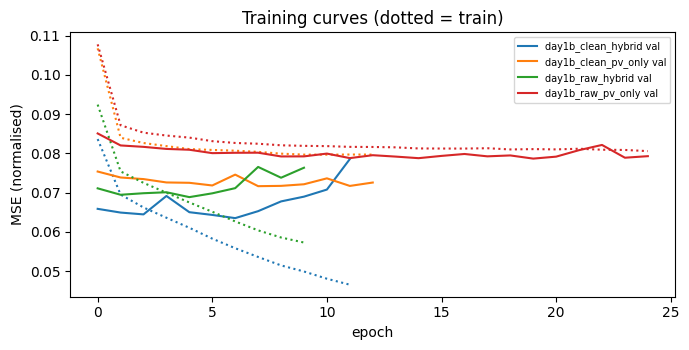

In [14]:
PREDS = {}
for tag, model in MODELS.items():
    data_tag = tag.split('_')[1]; mu, sd = NORM[data_tag]
    for split_key, label in [('w_raw', 'raw test'), ('w_clean', 'clean test')]:
        w = TE[split_key]; y = TE['pv'][w + HORIZON]
        p = predict(model, TE, w, mu, sd)
        PREDS[(tag, label)] = p
        r, m = metrics(p, y); r_s, m_s = BASE[label]
        log_result(run=RUN, train_data=data_tag, test_set=label, model='CNN ' + tag.split('_', 2)[2].replace('_', '-'),
                   n=len(y), rmse=r, mae=m, skill_rmse_vs_smart=1 - r / r_s, skill_mae_vs_smart=1 - m / m_s,
                   notes='full train split, day-block val')

np.savez_compressed(f'{OUT}/{RUN}_prep.npz',
    tz=TZ, tr_w_clean=TR['w_clean'], tr_w_raw=TR['w_raw'], te_w_clean=TE['w_clean'], te_w_raw=TE['w_raw'],
    tr_good=TR['good'], te_good=TE['good'], norm_clean=np.array(NORM['clean']),
    **{f'pred__{t}__{l.replace(" ", "_")}': p for (t, l), p in PREDS.items()})

fig, ax = plt.subplots(figsize=(7, 3.6))
for tag, h in HISTS.items():
    h = np.array(h); ax.plot(h[:, 1], label=f'{tag} val'); ax.plot(h[:, 0], ls=':', color=ax.lines[-1].get_color())
ax.set_xlabel('epoch'); ax.set_ylabel('MSE (normalised)'); ax.set_title('Training curves (dotted = train)'); ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig(f'{OUT}/figs/{RUN}_training_curves.png', dpi=150); plt.show()

## 7. Summary

In [15]:
res = pd.read_csv(RESULTS_CSV)
res = res[res.run == RUN].drop_duplicates(['train_data', 'test_set', 'model'], keep='last')
tbl = res.pivot_table(index=['model', 'train_data'], columns='test_set', values=['rmse', 'mae', 'skill_rmse_vs_smart'], aggfunc='first')
print(tbl.round(3).to_string())
tbl.round(3).to_csv(f'{OUT}/{RUN}_summary.csv')
print(f'\nTimezone used: {TZ}.  Files saved in {OUT}: audit_flags.csv, windows_raw_vs_clean.csv, timezone_check.csv, {RUN}_summary.csv, results.csv, figs/')

                                                    mae                rmse          skill_rmse_vs_smart         
test_set                                     clean test raw test clean test raw test          clean test raw test
model                             train_data                                                                     
CNN hybrid                        clean           1.470    1.599      2.786    3.049               0.138    0.155
                                  raw             1.493    1.611      2.796    3.019               0.135    0.164
CNN pv-only                       clean           1.513    1.653      2.978    3.232               0.079    0.105
                                  raw             1.499    1.637      2.975    3.232               0.080    0.105
naive persistence                 -               1.982    2.145      3.375    3.743              -0.044   -0.037
smart persistence                 -               1.474    1.634      3.233    3.609    